# Dual 10x10 Gridworld with Adjacency Matrix

This notebook creates a dual-gridworld system with:
- First 10x10 grid with agent (🤖) and intermediate goal (⭐)
- Second 10x10 grid accessible through intermediate goal, containing final goal (🎯)
- Adjacency matrix representation with 4-directional connectivity
- Semi-permeable door at intermediate goal connecting the two grids
- Self-absorbing final goal state

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import matplotlib.patches as patches
import seaborn as sns
from scipy.sparse import csr_matrix

## Configuration

**Change these coordinates to move the elements around the gridworld:**

In [ ]:
# Grid configuration
GRID_SIZE = 10
TOTAL_STATES = 3 * GRID_SIZE * GRID_SIZE  # Three 10x10 grids = 300 states

# Positions (row, column) - coordinates are (0,0) to (9,9)
AGENT_POS = (0, 0)                        # Starting position of agent (Layer 0)
INTERMEDIATE_GOAL_1_POS = (4, 5)          # First intermediate goal (Layer 0 → Layer 1)
INTERMEDIATE_GOAL_2_POS = (7, 2)          # Second intermediate goal (Layer 1 → Layer 2)
GOAL_POS = (9, 9)                         # Final goal position (Layer 2, self-absorbing)

# State indexing: 
# Layer 0 (start) = states 0-99
# Layer 1 (after 1st goal) = states 100-199  
# Layer 2 (after 2nd goal, final goal here) = states 200-299
# State index = layer_id * 100 + row * 10 + col

# Colors and symbols
AGENT_COLOR = '#4CAF50'           # Green
GOAL_COLOR = '#F44336'            # Red
INTERMEDIATE_1_COLOR = '#FF9800'  # Orange
INTERMEDIATE_2_COLOR = '#9C27B0'  # Purple
GRID_COLOR = '#E0E0E0'            # Light gray

## State Indexing Functions

In [ ]:
def pos_to_state(row, col, layer_id=0):
    """Convert (row, col, layer_id) to state index."""
    return layer_id * (GRID_SIZE * GRID_SIZE) + row * GRID_SIZE + col

def state_to_pos(state):
    """Convert state index to (row, col, layer_id)."""
    layer_id = state // (GRID_SIZE * GRID_SIZE)
    remaining = state % (GRID_SIZE * GRID_SIZE)
    row = remaining // GRID_SIZE
    col = remaining % GRID_SIZE
    return row, col, layer_id

def get_valid_neighbors(row, col):
    """Get valid 4-directional neighbors within grid bounds."""
    neighbors = []
    # North, South, East, West
    directions = [(-1, 0), (1, 0), (0, 1), (0, -1)]
    
    for dr, dc in directions:
        new_row, new_col = row + dr, col + dc
        if 0 <= new_row < GRID_SIZE and 0 <= new_col < GRID_SIZE:
            neighbors.append((new_row, new_col))
    
    return neighbors

## Adjacency Matrix Generation

In [ ]:
def create_adjacency_matrix():
    """
    Create adjacency matrix for sequential goal dependency system.
    
    Rules:
    1. Each grid cell connects bilaterally to N,S,E,W neighbors within the same layer
    2. First intermediate goal connects Layer 0 → Layer 1
    3. Second intermediate goal connects Layer 1 → Layer 2  
    4. Goal location is STRICTLY self-absorbing in ALL layers (only self-loop)
    5. Sequential dependency: Must reach goals in order
    
    Layers:
    - Layer 0: Starting layer (states 0-99)
    - Layer 1: After 1st intermediate goal (states 100-199)
    - Layer 2: After 2nd intermediate goal, contains final goal (states 200-299)
    
    Returns:
        adjacency_matrix: 300x300 sparse matrix
        state_info: dictionary with state information
    """
    # Initialize adjacency matrix
    adj_matrix = np.zeros((TOTAL_STATES, TOTAL_STATES))
    
    # Create standard 4-directional connectivity within each layer
    for layer_id in range(3):
        for row in range(GRID_SIZE):
            for col in range(GRID_SIZE):
                current_state = pos_to_state(row, col, layer_id=layer_id)
                neighbors = get_valid_neighbors(row, col)
                
                for neighbor_row, neighbor_col in neighbors:
                    neighbor_state = pos_to_state(neighbor_row, neighbor_col, layer_id=layer_id)
                    adj_matrix[current_state, neighbor_state] = 1
    
    # Sequential goal transitions
    # 1st intermediate goal: Layer 0 → Layer 1
    int_goal_1_layer0 = pos_to_state(INTERMEDIATE_GOAL_1_POS[0], INTERMEDIATE_GOAL_1_POS[1], layer_id=0)
    int_goal_1_layer1 = pos_to_state(INTERMEDIATE_GOAL_1_POS[0], INTERMEDIATE_GOAL_1_POS[1], layer_id=1)
    adj_matrix[int_goal_1_layer0, int_goal_1_layer1] = 1
    
    # 2nd intermediate goal: Layer 1 → Layer 2 (only accessible after 1st goal)
    int_goal_2_layer1 = pos_to_state(INTERMEDIATE_GOAL_2_POS[0], INTERMEDIATE_GOAL_2_POS[1], layer_id=1)
    int_goal_2_layer2 = pos_to_state(INTERMEDIATE_GOAL_2_POS[0], INTERMEDIATE_GOAL_2_POS[1], layer_id=2)
    adj_matrix[int_goal_2_layer1, int_goal_2_layer2] = 1
    
    # Make goal location self-absorbing in every layer
    for layer_id in range(3):
        goal_state = pos_to_state(GOAL_POS[0], GOAL_POS[1], layer_id=layer_id)
        # Remove all outgoing connections from goal state
        adj_matrix[goal_state, :] = 0
        # Add only the self-loop for goal
        adj_matrix[goal_state, goal_state] = 1
    
    # Create state info dictionary
    state_info = {
        'agent_state': pos_to_state(AGENT_POS[0], AGENT_POS[1], layer_id=0),
        'intermediate_1_layer0': int_goal_1_layer0,
        'intermediate_1_layer1': int_goal_1_layer1,
        'intermediate_2_layer1': int_goal_2_layer1,
        'intermediate_2_layer2': int_goal_2_layer2,
        'final_goal_layer2': pos_to_state(GOAL_POS[0], GOAL_POS[1], layer_id=2),
        'goal_layer0': pos_to_state(GOAL_POS[0], GOAL_POS[1], layer_id=0),
        'goal_layer1': pos_to_state(GOAL_POS[0], GOAL_POS[1], layer_id=1),
        'total_states': TOTAL_STATES,
        'grid_size': GRID_SIZE,
        'num_layers': 3
    }
    
    return csr_matrix(adj_matrix), state_info

## Visualization Functions

In [ ]:
def visualize_single_gridworld():
    """Visualize single gridworld with sequential intermediate goals."""
    fig, ax = plt.subplots(1, 1, figsize=(12, 10))
    
    # Create the grid
    for i in range(GRID_SIZE + 1):
        ax.axhline(i, color=GRID_COLOR, linewidth=1)
        ax.axvline(i, color=GRID_COLOR, linewidth=1)
    
    # Add agent
    agent_rect = Rectangle(
        (AGENT_POS[1], GRID_SIZE - 1 - AGENT_POS[0]), 
        1, 1, facecolor=AGENT_COLOR, alpha=0.7, edgecolor='black', linewidth=2
    )
    ax.add_patch(agent_rect)
    ax.text(AGENT_POS[1] + 0.5, GRID_SIZE - 1 - AGENT_POS[0] + 0.5, '🤖', 
             fontsize=20, ha='center', va='center')
    
    # Add first intermediate goal
    intermediate_1_rect = Rectangle(
        (INTERMEDIATE_GOAL_1_POS[1], GRID_SIZE - 1 - INTERMEDIATE_GOAL_1_POS[0]), 
        1, 1, facecolor=INTERMEDIATE_1_COLOR, alpha=0.7, edgecolor='black', linewidth=2
    )
    ax.add_patch(intermediate_1_rect)
    ax.text(INTERMEDIATE_GOAL_1_POS[1] + 0.5, GRID_SIZE - 1 - INTERMEDIATE_GOAL_1_POS[0] + 0.5, '⭐', 
             fontsize=20, ha='center', va='center')
    
    # Add second intermediate goal  
    intermediate_2_rect = Rectangle(
        (INTERMEDIATE_GOAL_2_POS[1], GRID_SIZE - 1 - INTERMEDIATE_GOAL_2_POS[0]), 
        1, 1, facecolor=INTERMEDIATE_2_COLOR, alpha=0.7, edgecolor='black', linewidth=2
    )
    ax.add_patch(intermediate_2_rect)
    ax.text(INTERMEDIATE_GOAL_2_POS[1] + 0.5, GRID_SIZE - 1 - INTERMEDIATE_GOAL_2_POS[0] + 0.5, '💎', 
             fontsize=20, ha='center', va='center')
    
    # Add final goal
    goal_rect = Rectangle(
        (GOAL_POS[1], GRID_SIZE - 1 - GOAL_POS[0]), 
        1, 1, facecolor=GOAL_COLOR, alpha=0.7, edgecolor='black', linewidth=2
    )
    ax.add_patch(goal_rect)
    ax.text(GOAL_POS[1] + 0.5, GRID_SIZE - 1 - GOAL_POS[0] + 0.5, '🎯', 
             fontsize=20, ha='center', va='center')
    
    # Set up the plot
    ax.set_xlim(0, GRID_SIZE)
    ax.set_ylim(0, GRID_SIZE)
    ax.set_aspect('equal')
    ax.set_title('10x10 Gridworld (300 States: 3 layers with Sequential Dependencies)', fontsize=16, fontweight='bold')
    ax.set_xlabel('Column')
    ax.set_ylabel('Row (flipped)')
    
    # Set ticks
    ax.set_xticks(range(GRID_SIZE + 1))
    ax.set_yticks(range(GRID_SIZE + 1))
    
    # Add legend
    legend_elements = [
        patches.Patch(color=AGENT_COLOR, label='Agent 🤖 (Start Layer 0)'),
        patches.Patch(color=INTERMEDIATE_1_COLOR, label='1st Goal ⭐ (Layer 0→1)'),
        patches.Patch(color=INTERMEDIATE_2_COLOR, label='2nd Goal 💎 (Layer 1→2)'),
        patches.Patch(color=GOAL_COLOR, label='Final Goal 🎯 (Layer 2, Absorbing)')
    ]
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1))
    
    # Add state space and dependency info
    info_text = (f"State Space: 300 total states\n"
                f"Layer 0: States 0-99 (Start)\n"
                f"Layer 1: States 100-199 (After ⭐)\n"
                f"Layer 2: States 200-299 (After 💎, Final Goal)\n\n"
                f"Sequential Dependencies:\n"
                f"🤖 → ⭐ → 💎 → 🎯\n\n"
                f"Key States:\n"
                f"Agent: {pos_to_state(AGENT_POS[0], AGENT_POS[1], 0)}\n"
                f"1st Goal: {pos_to_state(INTERMEDIATE_GOAL_1_POS[0], INTERMEDIATE_GOAL_1_POS[1], 0)} → {pos_to_state(INTERMEDIATE_GOAL_1_POS[0], INTERMEDIATE_GOAL_1_POS[1], 1)}\n"
                f"2nd Goal: {pos_to_state(INTERMEDIATE_GOAL_2_POS[0], INTERMEDIATE_GOAL_2_POS[1], 1)} → {pos_to_state(INTERMEDIATE_GOAL_2_POS[0], INTERMEDIATE_GOAL_2_POS[1], 2)}\n"
                f"Final: {pos_to_state(GOAL_POS[0], GOAL_POS[1], 2)} (Self-absorbing)")
    
    ax.text(
        1.02, 0.5, info_text, 
        transform=ax.transAxes, 
        fontsize=10, 
        verticalalignment='center',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8)
    )
    
    plt.tight_layout()
    plt.show()
    
    return fig, ax

def visualize_adjacency_matrix(adj_matrix, max_states_to_show=50):
    """Visualize a subset of the adjacency matrix."""
    # Show only first max_states_to_show x max_states_to_show for readability
    subset = adj_matrix[:max_states_to_show, :max_states_to_show].toarray()
    
    plt.figure(figsize=(12, 10))
    sns.heatmap(subset, cmap='Blues', cbar=True, square=True, 
                xticklabels=5, yticklabels=5)
    plt.title(f'Adjacency Matrix (First {max_states_to_show}x{max_states_to_show} states)')
    plt.xlabel('To State')
    plt.ylabel('From State')
    plt.show()

## Generate and Display Results

Adjacency Matrix Shape: (300, 300)
Number of connections: 1081

Key States:
Agent starting state: 0
1st Goal (Layer 0): 45
1st Goal (Layer 1): 145
2nd Goal (Layer 1): 172
2nd Goal (Layer 2): 272
Final Goal (Layer 2): 299


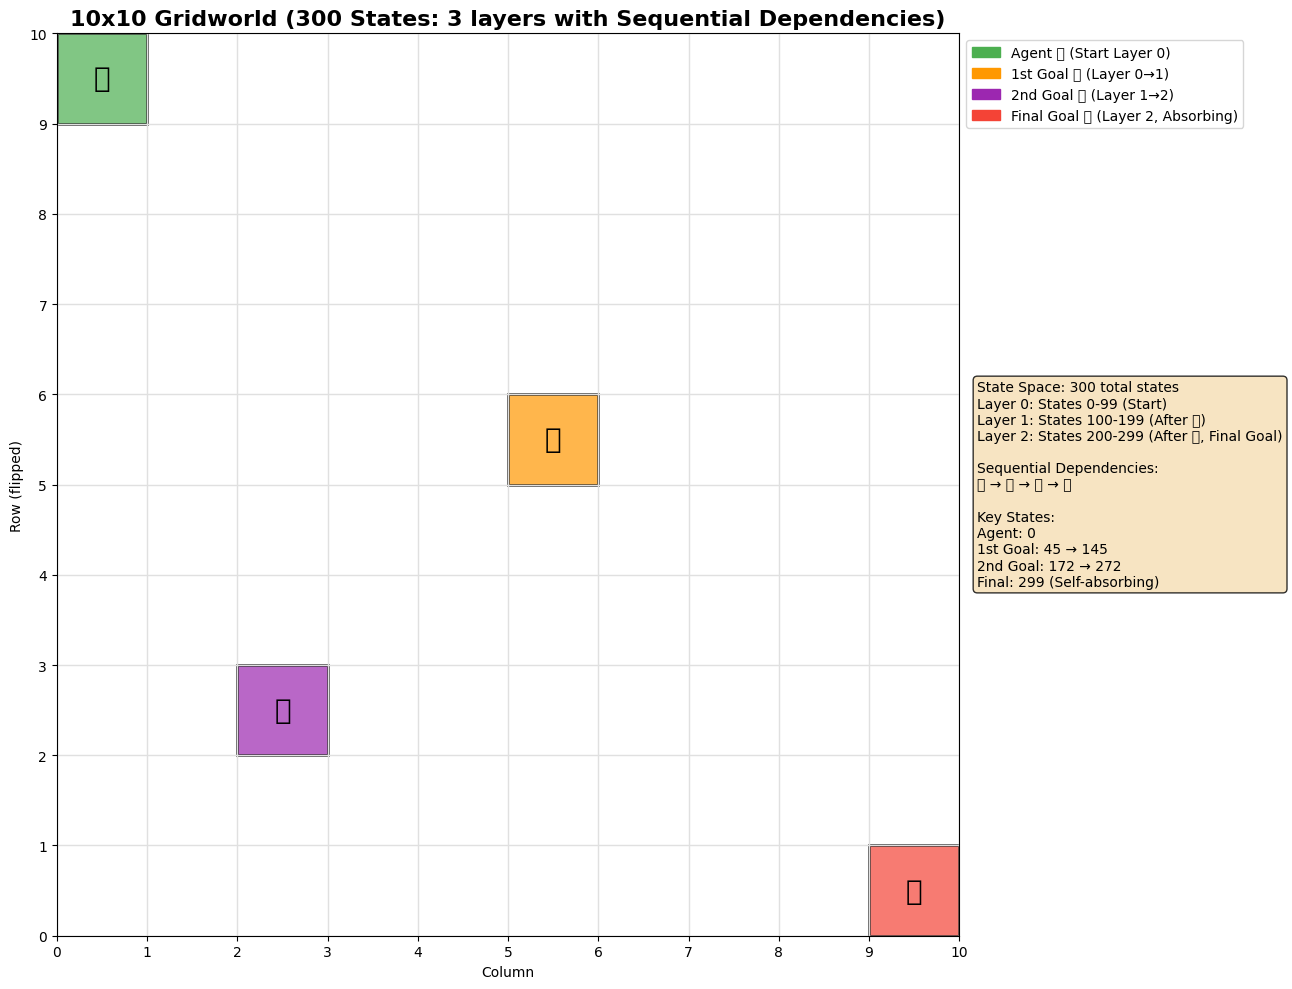

In [ ]:
# Create adjacency matrix
adj_matrix, state_info = create_adjacency_matrix()

# Display information
print(f"Adjacency Matrix Shape: {adj_matrix.shape}")
print(f"Number of connections: {adj_matrix.nnz}")
print(f"\nKey States:")
print(f"Agent starting state: {state_info['agent_state']}")
print(f"1st Goal (Layer 0): {state_info['intermediate_1_layer0']}")
print(f"1st Goal (Layer 1): {state_info['intermediate_1_layer1']}")
print(f"2nd Goal (Layer 1): {state_info['intermediate_2_layer1']}")
print(f"2nd Goal (Layer 2): {state_info['intermediate_2_layer2']}")
print(f"Final Goal (Layer 2): {state_info['final_goal_layer2']}")

# Visualize the single gridworld with sequential dependencies
fig_grid, ax = visualize_single_gridworld()

## Adjacency Matrix Analysis

In [ ]:
# Visualize adjacency matrix (first 50x50 subset)
visualize_adjacency_matrix(adj_matrix, max_states_to_show=300)

# Analyze connectivity
def analyze_sequential_connectivity(adj_matrix, state_info):
    """Analyze the connectivity properties of the sequential goal system."""
    print("\n=== Sequential Goal Connectivity Analysis ===")
    
    # Check agent connections
    agent_state = state_info['agent_state']
    agent_connections = adj_matrix[agent_state, :].nonzero()[1]
    print(f"\nAgent state {agent_state} connections:")
    print(f"  Connected to {len(agent_connections)} states: {agent_connections[:10]}...")
    
    # Check 1st intermediate goal connections
    int1_l0 = state_info['intermediate_1_layer0']
    int1_l1 = state_info['intermediate_1_layer1']
    int1_l0_connections = adj_matrix[int1_l0, :].nonzero()[1]
    print(f"\n1st Goal Layer 0 (state {int1_l0}) connections:")
    print(f"  Connected to {len(int1_l0_connections)} states: {int1_l0_connections}")
    
    # Check 2nd intermediate goal connections  
    int2_l1 = state_info['intermediate_2_layer1']
    int2_l2 = state_info['intermediate_2_layer2']
    int2_l1_connections = adj_matrix[int2_l1, :].nonzero()[1]
    print(f"\n2nd Goal Layer 1 (state {int2_l1}) connections:")
    print(f"  Connected to {len(int2_l1_connections)} states: {int2_l1_connections}")
    
    # Check goal connections in all layers
    goal_l0 = state_info['goal_layer0']
    goal_l1 = state_info['goal_layer1']
    goal_l2 = state_info['final_goal_layer2']
    
    goal_l0_connections = adj_matrix[goal_l0, :].nonzero()[1]
    goal_l1_connections = adj_matrix[goal_l1, :].nonzero()[1]
    goal_l2_connections = adj_matrix[goal_l2, :].nonzero()[1]
    
    print(f"\nGoal Layer 0 (state {goal_l0}) connections (should only be self-loop):")
    print(f"  Connected to {len(goal_l0_connections)} states: {goal_l0_connections}")
    
    print(f"\nGoal Layer 1 (state {goal_l1}) connections (should only be self-loop):")
    print(f"  Connected to {len(goal_l1_connections)} states: {goal_l1_connections}")
    
    print(f"\nGoal Layer 2 (state {goal_l2}) connections (should only be self-loop):")
    print(f"  Connected to {len(goal_l2_connections)} states: {goal_l2_connections}")
    
    # Check sequential transitions
    seq_transitions = []
    seq_transitions.append(adj_matrix[int1_l0, int1_l1] == 1)  # 1st goal transition
    seq_transitions.append(adj_matrix[int2_l1, int2_l2] == 1)  # 2nd goal transition  
    
    print(f"\nSequential Transitions:")
    print(f"  1st Goal (L0→L1): {seq_transitions[0]}")
    print(f"  2nd Goal (L1→L2): {seq_transitions[1]}")
    
    # Check if all goal states are properly absorbing
    all_goals_absorbing = (
        len(goal_l0_connections) == 1 and goal_l0_connections[0] == goal_l0 and
        len(goal_l1_connections) == 1 and goal_l1_connections[0] == goal_l1 and
        len(goal_l2_connections) == 1 and goal_l2_connections[0] == goal_l2
    )
    
    return {
        'all_transitions_exist': all(seq_transitions),
        'all_goals_absorbing': all_goals_absorbing,
        'final_goal_is_absorbing': len(goal_l2_connections) == 1 and goal_l2_connections[0] == goal_l2,
        'num_layers': state_info['num_layers']
    }

# Run analysis
connectivity_stats = analyze_sequential_connectivity(adj_matrix, state_info)

print("\n=== Summary ===")
print(f"Total states: {TOTAL_STATES}")
print(f"Number of layers: {connectivity_stats['num_layers']}")
print(f"Total connections: {adj_matrix.nnz}")
print(f"Average connections per state: {adj_matrix.nnz / TOTAL_STATES:.2f}")
print(f"Matrix density: {adj_matrix.nnz / (TOTAL_STATES ** 2) * 100:.4f}%")
print(f"All sequential transitions exist: {connectivity_stats['all_transitions_exist']}")
print(f"All goals properly absorbing: {connectivity_stats['all_goals_absorbing']}")
print(f"Sequential dependency enforced: 🤖 → ⭐ → 💎 → 🎯")

In [ ]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# Create graph from adjacency matrix
# Convert sparse matrix to dense for NetworkX
if hasattr(adj_matrix, 'toarray'):
    adj_dense = adj_matrix.toarray()
else:
    adj_dense = adj_matrix

G = nx.from_numpy_array(adj_dense)

# # Visualize the graph
# plt.figure(figsize=(8, 6))
# nx.draw(G, with_labels=False, node_color='lightblue', 
#         node_size=20, font_size=16, font_weight='bold')
# plt.title("Graph from Adjacency Matrix")
# plt.show()

# # # Spring layout with parameters tuned for spreading
pos_spread = nx.spring_layout(G, 
                             seed=42,
                             k=.50000,        # Increase optimal distance
                             iterations=1000,
                        #      repulsive_k=0.1
                        
                        )  # Increase repulsion
                        

plt.figure(figsize=(10, 10))

nx.draw(G, pos_spread, with_labels=False, node_color='lightblue', 
        node_size=32, font_size=12)
plt.title("Graph from Adjacency Matrix")
plt.show()

In [ ]:
# If you know your adjacency matrix represents a specific grid pattern
def custom_lattice_layout(adj_matrix):
    """
    Create positions based on adjacency matrix structure
    Assumes lattice-like connectivity
    """
    # Convert sparse matrix to dense for NetworkX
    if hasattr(adj_matrix, 'toarray'):
        adj_dense = adj_matrix.toarray()
    else:
        adj_dense = adj_matrix
    
    G = nx.from_numpy_array(adj_dense)
    n_nodes = adj_matrix.shape[0]  # Use shape[0] instead of len()
    
    # Try to infer grid dimensions
    sqrt_n = int(np.sqrt(n_nodes))
    if sqrt_n * sqrt_n == n_nodes:
        # Square grid
        pos = {}
        for i in range(n_nodes):
            row = i // sqrt_n
            col = i % sqrt_n
            pos[i] = (col * 2, -row * 2)  # Scale by 2 for more space
    else:
        # Fall back to spring layout with good spacing
        pos = nx.spring_layout(G, seed=42, k=3.0, iterations=150)
    
    return G, pos

# # Example with your adjacency matrix
# adj_matrix = np.array([
#     [0, 1, 0, 1, 0],
#     [1, 0, 1, 0, 1],
#     [0, 1, 0, 1, 0],
#     [1, 0, 1, 0, 1],
#     [0, 1, 0, 1, 0]
# ])

G, pos = custom_lattice_layout(adj_matrix)

plt.figure(figsize=(12, 8))
nx.draw(G, pos, with_labels=True, node_color='yellow',
        node_size=800, font_size=14, font_weight='bold',
        edge_color='gray', width=2)
plt.title("Custom Lattice Layout")
plt.axis('equal')
plt.show()